# 🌿📱 HPDC-Net: Edge Device-Friendly CNN for Plant Leaf Disease Classification 🌾🧠

Welcome to the **HPDC-Net** 👨‍🔬🧪  
A **High-Performance Disease Classification Network (HPDC-Net)** designed for real-time, on-device plant disease detection using leaf images.  

---

## 🌟 Key Features of HPDC-Net

🔹 **Lightweight Architecture** – Perfect for edge deployment on mobile or IoT devices (Raspberry Pi, Jetson Nano).  
🔹 **High Accuracy** – Designed for robust performance on small datasets of plant leaf images.  
🔹 **Optimized Inference** – Fast and efficient with low memory and power usage.  
🔹 **Smart Feature Extraction** – Includes novel modules for capturing disease-specific patterns in leaf texture and color.  




## 📂 Dataset Loading and Preparation 🌿🧪

In this section, we will load and prepare the **Plant Leaf Disease Dataset** for training and evaluation using **PyTorch**. The dataset includes multiple classes such as healthy and diseased leaves from various crops. 🍅🍇🌾


Potato___Early_blight: 1000 images
Potato___healthy: 152 images
Potato___Late_blight: 1000 images


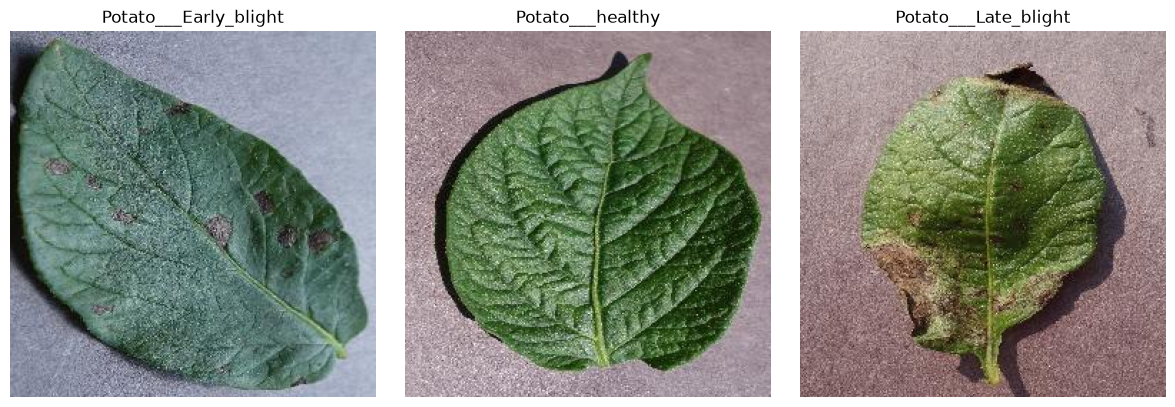

In [7]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

dataset_path = Path(
    r"D:\MR A2\BRIDGE-AI\dataset\dataset\Plant_leave_diseases_dataset_without_augmentation"
)

classes = [
    "Potato___Early_blight",
    "Potato___healthy",
    "Potato___Late_blight"
]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, class_name in zip(axes, classes):
    folder = dataset_path / class_name

    images = [
        p for p in folder.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    print(f"{class_name}: {len(images)} images")

    with Image.open(images[0]) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [2]:
!wget "https://data.mendeley.com/public-files/datasets/tywbtsjrjv/files/d5652a28-c1d8-4b76-97f3-72fb80f94efc/file_downloaded"

'wget' n'est pas reconnu en tant que commande interne
ou externe, un programme ex�cutable ou un fichier de commandes.


In [ ]:
!unzip "/content/file_downloaded";

In [ ]:
# import shutil
# shutil.rmtree('tomato')

In [9]:

import os
import shutil

# Original dataset directory (Windows)
directory = r"D:\MR A2\BRIDGE-AI\dataset\dataset\Plant_leave_diseases_dataset_without_augmentation"

# Destination directory for tomato classes
destination = r"D:\MR A2\BRIDGE-AI\dataset\tomato_source"

os.makedirs(destination, exist_ok=True)

# Get a list of all folders
folders = [
    f for f in os.listdir(directory)
    if os.path.isdir(os.path.join(directory, f))
]

# Keep only tomato classes without deleting the original data
for folder in folders:
    if "tomato" in folder.lower():
        source_path = os.path.join(directory, folder)
        destination_path = os.path.join(destination, folder)

        if not os.path.exists(destination_path):
            shutil.copytree(source_path, destination_path)
            print(f"Copied: {folder}")
        else:
            print(f"Already exists: {folder}")

print("\nTomato dataset preparation completed.")


Already exists: Tomato___Bacterial_spot
Already exists: Tomato___Early_blight
Already exists: Tomato___healthy
Already exists: Tomato___Late_blight
Already exists: Tomato___Leaf_Mold
Already exists: Tomato___Septoria_leaf_spot
Already exists: Tomato___Spider_mites Two-spotted_spider_mite
Already exists: Tomato___Target_Spot
Already exists: Tomato___Tomato_mosaic_virus
Already exists: Tomato___Tomato_Yellow_Leaf_Curl_Virus

Tomato dataset preparation completed.


In [11]:

# Split dataset - HPDC-Net original method

import os
import splitfolders

# Dataset containing only tomato classes
base_dir = r"D:\MR A2\BRIDGE-AI\dataset\tomato_source"

# Destination for train, validation and test
output_dir = r"D:\MR A2\BRIDGE-AI\dataset\tomato_split"

# Original authors' parameters
splitfolders.ratio(
    base_dir,
    output=output_dir,
    seed=1314,
    ratio=(.7, .2, .1)
)

train_dir = os.path.join(output_dir, 'train')
validation_dir = os.path.join(output_dir, 'val')
test_dir = os.path.join(output_dir, 'test')

print("Dataset successfully split!")
print("Train:", train_dir)
print("Validation:", validation_dir)
print("Test:", test_dir)


Copying files: 18160 files [00:36, 496.63 files/s]

Dataset successfully split!
Train: D:\MR A2\BRIDGE-AI\dataset\tomato_split\train
Validation: D:\MR A2\BRIDGE-AI\dataset\tomato_split\val
Test: D:\MR A2\BRIDGE-AI\dataset\tomato_split\test


In [13]:

import os
import random
import torch
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader


# Function to set seed for reproducibility
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)  # if you are using multi-GPU.
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


# Set seed
seed = 42
set_seed(seed)

# Define the root directory of the dataset
data_dir = r"D:\MR A2\BRIDGE-AI\dataset\tomato_split"

# Define transformations for training, validation, and testing sets
train_transforms = transforms.Compose(
    [
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]
)

valid_test_transforms = transforms.Compose(
    [
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]
)

# Load datasets with ImageFolder
train_dataset = datasets.ImageFolder(
    os.path.join(data_dir, "train"), transform=train_transforms
)
valid_dataset = datasets.ImageFolder(
    os.path.join(data_dir, "val"), transform=valid_test_transforms
)
test_dataset = datasets.ImageFolder(
    os.path.join(data_dir, "test"), transform=valid_test_transforms
)

# Define data loaders
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Print the number of classes
print(f"Number of classes: {len(train_dataset.classes)}")
print(f"Class names: {train_dataset.classes}")


Number of classes: 10
Class names: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']


In [ ]:
!pip install thop

🌱🧠 **HPDCNet** is a lightweight convolutional neural network that combines depthwise adaptive residuals, hybrid pooling, and conditional feature enhancement. Designed for efficient and robust visual recognition, it fuses multi-scale features with recalibrated attention for superior performance.
### 🔬 Potential Applications:

✅ Smart Farming  
✅ Mobile Disease Detection Apps  
✅ Precision Agriculture  
✅ Drone Crop Monitoring  


In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# --- Block Definitions ---

class DepthwiseAdaptiveResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(DepthwiseAdaptiveResidualBlock, self).__init__()
        self.depthwise = nn.Conv2d(
            in_channels, in_channels, kernel_size=3, stride=stride, padding=1, groups=in_channels
        )
        self.pointwise = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        self.bn = nn.BatchNorm2d(out_channels)
        self.shortcut = nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride) if in_channels != out_channels else nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)
        x = self.depthwise(x)
        x = self.pointwise(x)
        x = self.bn(x)
        return F.relu(x + identity)


class FeatureRecalibrationAttention(nn.Module):
    def __init__(self, in_channels):
        super(FeatureRecalibrationAttention, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, in_channels, kernel_size=1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        attention = self.sigmoid(self.conv1(x))
        return x * attention


class MultiScaleFusionBlock(nn.Module):
    def __init__(self, in_channels):
        super(MultiScaleFusionBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, in_channels, kernel_size=1)
        self.conv3 = nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(in_channels, in_channels, kernel_size=5, padding=2)

    def forward(self, x):
        x1 = self.conv1(x)
        x3 = self.conv3(x)
        x5 = self.conv5(x)
        return x1 + x3 + x5


class HybridPoolingLayer(nn.Module):
    def __init__(self, kernel_size=2, stride=2):
        super(HybridPoolingLayer, self).__init__()
        self.max_pool = nn.MaxPool2d(kernel_size, stride)
        self.avg_pool = nn.AvgPool2d(kernel_size, stride)

    def forward(self, x):
        max_pooled = self.max_pool(x)
        avg_pooled = self.avg_pool(x)
        return (max_pooled + avg_pooled) / 2


class ConditionalFeatureEnhancement(nn.Module):
    def __init__(self, in_channels, reduction=16):
        super(ConditionalFeatureEnhancement, self).__init__()
        self.global_avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc1 = nn.Linear(in_channels, in_channels // reduction)
        self.fc2 = nn.Linear(in_channels // reduction, in_channels)

    def forward(self, x):
        b, c, _, _ = x.size()
        weights = self.global_avg_pool(x).view(b, c)
        weights = F.relu(self.fc1(weights))
        weights = torch.sigmoid(self.fc2(weights)).view(b, c, 1, 1)
        return x * weights


# --- HPDC-Net ---

class HPDCNet(nn.Module):
    def __init__(self, num_classes=10):
        super(HPDCNet, self).__init__()
        # Stage 1
        self.layer1 = DepthwiseAdaptiveResidualBlock(3, 16)
        self.attn1 = FeatureRecalibrationAttention(16)
        self.pool1 = HybridPoolingLayer()

        # Stage 2
        self.layer2 = DepthwiseAdaptiveResidualBlock(16, 32)
        self.attn2 = FeatureRecalibrationAttention(32)
        self.pool2 = HybridPoolingLayer()

        # Stage 3
        self.layer3 = DepthwiseAdaptiveResidualBlock(32, 64)
        self.fusion3 = MultiScaleFusionBlock(64)
        self.attn3 = FeatureRecalibrationAttention(64)
        self.pool3 = HybridPoolingLayer()

        # Stage 4
        self.layer4 = DepthwiseAdaptiveResidualBlock(64, 128)
        self.fusion4 = MultiScaleFusionBlock(128)
        self.attn4 = FeatureRecalibrationAttention(128)

        # Classifier
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        # Stage 1
        x = self.layer1(x)
        x = self.attn1(x)
        x = self.pool1(x)

        # Stage 2
        x = self.layer2(x)
        x = self.attn2(x)
        x = self.pool2(x)

        # Stage 3
        x = self.layer3(x)
        x = self.fusion3(x)
        x = self.attn3(x)
        x = self.pool3(x)

        # Stage 4
        x = self.layer4(x)
        x = self.fusion4(x)
        x = self.attn4(x)

        # Classifier
        x = self.global_pool(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


# Model Summary
if __name__ == "__main__":
    model = HPDCNet(num_classes=3)
    sample_input = torch.randn(1, 3, 224, 224)
    output = model(sample_input)
    print("Output shape:", output.shape)
    print("Model Summary:")
    from thop import profile

    flops, params = profile(model, inputs=(sample_input,))
    print(f"GFLOPs: {flops / 1e9:.2f}")
    print(f"Number of parameters (in millions): {params / 1e6:.2f}")

Output shape: torch.Size([1, 3])
Model Summary:
[INFO] Register count_convNd() for <class 'torch.nn.modules.conv.Conv2d'>.
[INFO] Register count_normalization() for <class 'torch.nn.modules.batchnorm.BatchNorm2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.pooling.MaxPool2d'>.
[INFO] Register count_avgpool() for <class 'torch.nn.modules.pooling.AvgPool2d'>.
[INFO] Register count_adap_avgpool() for <class 'torch.nn.modules.pooling.AdaptiveAvgPool2d'>.
[INFO] Register count_linear() for <class 'torch.nn.modules.linear.Linear'>.
GFLOPs: 1.00
Number of parameters (in millions): 0.76


In [15]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = HPDCNet(num_classes=3).to(device)

print("Device :", device)
print("Modèle HPDC-Net chargé avec succès !")
print("Nombre de paramètres :", sum(p.numel() for p in model.parameters()))

Device : cuda
Modèle HPDC-Net chargé avec succès !
Nombre de paramètres : 763473


In [ ]:
!pip install tqdm torchmetrics


### 🏋️ Model Training Procedure

The `HPDCNet` model was trained for 200 epochs using the Adam optimizer with a learning rate of `0.001` and CrossEntropyLoss.  
Training and validation were conducted on a multi-class classification task with 10 classes.

**Training Pipeline:**
- Device: GPU
- Data: Loaded via `train_loader` and `valid_loader`
- Metrics: Accuracy, Precision, Recall, and F1 Score (macro average using TorchMetrics)
- Best model checkpoint saved based on highest validation accuracy


In [16]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from tqdm import tqdm
import torchmetrics

# Assume the dataset and data loaders are already defined
# Example:
# train_loader = ...
# valid_loader = ...

# Define the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Define the model
num_classes = 10  # Example number of classes
model = HPDCNet(num_classes).to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training and validation loop
num_epochs = 200

# Metrics
train_accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=num_classes).to(
    device
)
train_precision = torchmetrics.Precision(
    task="multiclass", num_classes=num_classes, average="macro"
).to(device)
train_recall = torchmetrics.Recall(
    task="multiclass", num_classes=num_classes, average="macro"
).to(device)
train_f1_score = torchmetrics.F1Score(
    task="multiclass", num_classes=num_classes, average="macro"
).to(device)

valid_accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=num_classes).to(
    device
)
valid_precision = torchmetrics.Precision(
    task="multiclass", num_classes=num_classes, average="macro"
).to(device)
valid_recall = torchmetrics.Recall(
    task="multiclass", num_classes=num_classes, average="macro"
).to(device)
valid_f1_score = torchmetrics.F1Score(
    task="multiclass", num_classes=num_classes, average="macro"
).to(device)

# Variable to track the best validation accuracy
best_val_accuracy = 0.0
best_epoch = 0

for epoch in range(num_epochs):
    # Training
    model.train()
    train_loss = 0
    train_accuracy.reset()
    train_precision.reset()
    train_recall.reset()
    train_f1_score.reset()

    for inputs, labels in tqdm(
        train_loader, desc=f"Training Epoch {epoch+1}/{num_epochs}"
    ):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * inputs.size(0)
        train_accuracy.update(outputs, labels)
        train_precision.update(outputs, labels)
        train_recall.update(outputs, labels)
        train_f1_score.update(outputs, labels)

    train_loss /= len(train_loader.dataset)
    train_accuracy_value = train_accuracy.compute().item()
    train_precision_value = train_precision.compute().item()
    train_recall_value = train_recall.compute().item()
    train_f1_value = train_f1_score.compute().item()

    # Validation
    model.eval()
    valid_loss = 0
    valid_accuracy.reset()
    valid_precision.reset()
    valid_recall.reset()
    valid_f1_score.reset()

    with torch.no_grad():
        for inputs, labels in tqdm(
            valid_loader, desc=f"Validation Epoch {epoch+1}/{num_epochs}"
        ):
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            valid_loss += loss.item() * inputs.size(0)
            valid_accuracy.update(outputs, labels)
            valid_precision.update(outputs, labels)
            valid_recall.update(outputs, labels)
            valid_f1_score.update(outputs, labels)

    valid_loss /= len(valid_loader.dataset)
    valid_accuracy_value = valid_accuracy.compute().item()
    valid_precision_value = valid_precision.compute().item()
    valid_recall_value = valid_recall.compute().item()
    valid_f1_value = valid_f1_score.compute().item()

    # Save the model if validation accuracy improves
    if valid_accuracy_value > best_val_accuracy:
        best_val_accuracy = valid_accuracy_value
        best_epoch = epoch + 1
        torch.save(model.state_dict(), "best_model.pth")
        print(
            f"New best model saved at epoch {epoch+1} with validation accuracy: {best_val_accuracy:.4f}"
        )

    print(f"Epoch {epoch+1}/{num_epochs}")
    print(f"Training Loss: {train_loss:.4f} | Validation Loss: {valid_loss:.4f}")
    print(
        f"Training Accuracy: {train_accuracy_value:.4f} | Validation Accuracy: {valid_accuracy_value:.4f}"
    )
    print(
        f"Training Precision: {train_precision_value:.4f} | Validation Precision: {valid_precision_value:.4f}"
    )
    print(
        f"Training Recall: {train_recall_value:.4f} | Validation Recall: {valid_recall_value:.4f}"
    )
    print(
        f"Training F1 Score: {train_f1_value:.4f} | Validation F1 Score: {valid_f1_value:.4f}"
    )

print(f"Best validation accuracy: {best_val_accuracy:.4f} at epoch {best_epoch}")

Validation Epoch 1/200: 100%|██████████| 114/114 [00:51<00:00,  2.20it/s]


New best model saved at epoch 1 with validation accuracy: 0.6789
Epoch 1/200
Training Loss: 1.1081 | Validation Loss: 0.9955
Training Accuracy: 0.6289 | Validation Accuracy: 0.6789
Training Precision: 0.5653 | Validation Precision: 0.6714
Training Recall: 0.5159 | Validation Recall: 0.6616
Training F1 Score: 0.5273 | Validation F1 Score: 0.6376


Validation Epoch 2/200: 100%|██████████| 114/114 [00:14<00:00,  7.75it/s]


New best model saved at epoch 2 with validation accuracy: 0.7064
Epoch 2/200
Training Loss: 0.7245 | Validation Loss: 0.8530
Training Accuracy: 0.7597 | Validation Accuracy: 0.7064
Training Precision: 0.7083 | Validation Precision: 0.7175
Training Recall: 0.6859 | Validation Recall: 0.6294
Training F1 Score: 0.6937 | Validation F1 Score: 0.6239


Validation Epoch 3/200: 100%|██████████| 114/114 [00:13<00:00,  8.15it/s]


New best model saved at epoch 3 with validation accuracy: 0.7922
Epoch 3/200
Training Loss: 0.5854 | Validation Loss: 0.5855
Training Accuracy: 0.8007 | Validation Accuracy: 0.7922
Training Precision: 0.7553 | Validation Precision: 0.7872
Training Recall: 0.7430 | Validation Recall: 0.7797
Training F1 Score: 0.7478 | Validation F1 Score: 0.7688


... (390 outputs left out)

Validation Epoch 199/200: 100%|██████████| 114/114 [00:14<00:00,  7.95it/s]


Epoch 199/200
Training Loss: 0.0600 | Validation Loss: 0.0645
Training Accuracy: 0.9803 | Validation Accuracy: 0.9862
Training Precision: 0.9758 | Validation Precision: 0.9841
Training Recall: 0.9745 | Validation Recall: 0.9824
Training F1 Score: 0.9751 | Validation F1 Score: 0.9831


Validation Epoch 200/200: 100%|██████████| 114/114 [00:13<00:00,  8.32it/s]


Epoch 200/200
Training Loss: 0.0593 | Validation Loss: 0.0353
Training Accuracy: 0.9800 | Validation Accuracy: 0.9906
Training Precision: 0.9758 | Validation Precision: 0.9890
Training Recall: 0.9750 | Validation Recall: 0.9888
Training F1 Score: 0.9754 | Validation F1 Score: 0.9889
Best validation accuracy: 0.9939 at epoch 146


In [5]:
variables = [
    "train_loader",
    "val_loader",
    "test_loader",
    "criterion",
    "optimizer"
]

for name in variables:
    print(
        f"{name} :",
        "Disponible" if name in globals() else "Non défini"
    )

train_loader : Non défini
val_loader : Non défini
test_loader : Non défini
criterion : Non défini
optimizer : Non défini


In [6]:

import torch
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

# 1. Chemin des images
dataset_path = r"D:\MR A2\BRIDGE-AI\dataset\dataset\Plant_leave_diseases_dataset_without_augmentation"

# 2. Prétraitement
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# 3. Charger uniquement les trois classes de pommes de terre
dataset = datasets.ImageFolder(
    root=dataset_path,
    transform=transform
)

potato_classes = [
    "Potato___Early_blight",
    "Potato___healthy",
    "Potato___Late_blight"
]

indices = [
    i for i, (_, label) in enumerate(dataset.samples)
    if dataset.classes[label] in potato_classes
]

labels = [
    dataset.samples[i][1]
    for i in indices
]

# 4. Découpage stratifié : 70 % / 15 % / 15 %
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

temp_labels = [
    dataset.samples[i][1]
    for i in temp_idx
]

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

# 5. Créer les DataLoaders
train_loader = DataLoader(
    Subset(dataset, train_idx),
    batch_size=16,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    Subset(dataset, val_idx),
    batch_size=16,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    Subset(dataset, test_idx),
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Classes sélectionnées :", potato_classes)
print("Train :", len(train_idx))
print("Validation :", len(val_idx))
print("Test :", len(test_idx))
print("Total :", len(indices))


Classes sélectionnées : ['Potato___Early_blight', 'Potato___healthy', 'Potato___Late_blight']
Train : 1506
Validation : 323
Test : 323
Total : 2152


### 🏋️ Model Training on CPU


In [ ]:
import os
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchmetrics
import time
import matplotlib.pyplot as plt
import numpy as np
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from sklearn.metrics import confusion_matrix
import seaborn as sns
import random

# Define the test dataset with ImageFolder to get class names
test_dataset = datasets.ImageFolder(
    os.path.join(data_dir, "test"), transform=valid_test_transforms
)
class_names = test_dataset.classes  # Extract class names from the folder names

# Force CPU usage
device = torch.device("cpu")

# Load the trained model
num_classes = len(class_names)
model = HPDCNet(num_classes).to(device)
model_path = "/content/best_model.pth"
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

# Define the test data loader
# test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Metrics
test_accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=num_classes).to(device)
test_precision = torchmetrics.Precision(task="multiclass", num_classes=num_classes, average="macro").to(device)
test_recall = torchmetrics.Recall(task="multiclass", num_classes=num_classes, average="macro").to(device)
test_f1_score = torchmetrics.F1Score(task="multiclass", num_classes=num_classes, average="macro").to(device)
test_confusion_matrix = torchmetrics.ConfusionMatrix(task="multiclass", num_classes=num_classes).to(device)

# Function to perform inference and calculate metrics
def perform_inference(device):
    model.to(device)
    test_accuracy.to(device)
    test_precision.to(device)
    test_recall.to(device)
    test_f1_score.to(device)
    test_confusion_matrix.to(device)

    inference_times = []
    all_labels = []
    all_predictions = []

    for i in range(5):
        test_accuracy.reset()
        test_precision.reset()
        test_recall.reset()
        test_f1_score.reset()
        test_confusion_matrix.reset()

        start_time = time.time()
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, predicted = torch.max(outputs, 1)

                test_accuracy.update(outputs, labels)
                test_precision.update(outputs, labels)
                test_recall.update(outputs, labels)
                test_f1_score.update(outputs, labels)
                test_confusion_matrix.update(predicted, labels)

                all_labels.extend(labels.cpu().numpy())
                all_predictions.extend(predicted.cpu().numpy())

        end_time = time.time()
        inference_times.append((end_time - start_time) * 1000)  # ms

    avg_inference_time = np.mean(inference_times) / len(test_loader.dataset)
    avg_accuracy = test_accuracy.compute().item()
    avg_precision = test_precision.compute().item()
    avg_recall = test_recall.compute().item()
    avg_f1 = test_f1_score.compute().item()
    cm = test_confusion_matrix.compute().cpu().numpy()

    return avg_accuracy, avg_precision, avg_recall, avg_f1, avg_inference_time, cm, all_labels, all_predictions

# Perform inference on CPU
(
    avg_accuracy_cpu,
    avg_precision_cpu,
    avg_recall_cpu,
    avg_f1_cpu,
    avg_inference_time_cpu,
    cm_cpu,
    labels_cpu,
    preds_cpu,
) = perform_inference(device)

fps_cpu = 1000 / avg_inference_time_cpu
print(f"CPU Average Test Accuracy: {avg_accuracy_cpu:.4f}")
print(f"CPU Average Test Precision: {avg_precision_cpu:.4f}")
print(f"CPU Average Test Recall: {avg_recall_cpu:.4f}")
print(f"CPU Average Test F1 Score: {avg_f1_cpu:.4f}")
print(f"CPU Average Inference Time per Image: {avg_inference_time_cpu:.6f} ms")
print(f"CPU Frames per Second: {fps_cpu:.2f}")

# Display confusion matrix
def plot_confusion_matrix(cm, class_names, title):
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
    )
    plt.xlabel("Predicted Labels")
    plt.ylabel("True Labels")
    plt.title(title)
    plt.show()

plot_confusion_matrix(cm_cpu, class_names, "CPU Confusion Matrix")


## 🧪 Visualizing Model Predictions on Sample Test Images

To better understand how the model performs on real data, we selected a set of 20 representative test images—two from each class (when available).

For each image, we performed forward inference and compared the **predicted label** against the **true label**:

- ✅ Correct predictions are shown with **green titles**
- ❌ Incorrect predictions are highlighted in **red**

The images are displayed in a grid layout for quick inspection. This visualization helps:

- Evaluate **class-wise performance**
- Identify **failure patterns**
- Visually inspect prediction **confidence and mistakes**


In [ ]:
import torch
import numpy as np
import random
import matplotlib.pyplot as plt
from torchvision import transforms

# Ensure device is correctly set
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Collect images by class
def collect_images_by_class(test_loader):
    class_indices = {i: [] for i in range(num_classes)}
    all_labels = []
    all_images = []

    for inputs, labels in test_loader:
        all_images.extend(inputs)
        all_labels.extend(labels)

    all_images = torch.stack(all_images).to(device)
    all_labels = torch.tensor(all_labels).to(device)

    for idx, label in enumerate(all_labels):
        class_indices[label.item()].append(idx)

    return class_indices, all_images, all_labels


# Get images by class
class_indices, all_images, all_labels = collect_images_by_class(test_loader)

# Select two images per class
selected_indices = []
for indices in class_indices.values():
    if len(indices) >= 2:
        selected_indices.extend(random.sample(indices, 2))
    else:
        selected_indices.extend(indices)

# Ensure we have 20 images
if len(selected_indices) < 20:
    remaining_indices = [i for i in range(len(all_labels)) if i not in selected_indices]
    additional_indices = random.sample(remaining_indices, 20 - len(selected_indices))
    selected_indices.extend(additional_indices)

# Gather the selected images and labels
selected_images = all_images[selected_indices]
selected_labels = all_labels[selected_indices]

# Perform inference on the selected images
with torch.no_grad():
    outputs = model(selected_images)
    _, predicted_labels = torch.max(outputs, 1)


# Plot images
def plot_image_with_labels(image, predicted_label, true_label, ax, class_names):
    image = inv_transform(image.cpu())
    ax.imshow(image)
    if predicted_label == true_label:
        ax.set_title(
            f"Pred: {class_names[predicted_label]}, True: {class_names[true_label]}",
            color="green",
        )
    else:
        ax.set_title(
            f"Pred: {class_names[predicted_label]}, True: {class_names[true_label]}",
            color="red",
        )
    ax.axis("off")


# Inverse transform for displaying images
inv_transform = transforms.Compose(
    [
        transforms.Normalize(
            mean=[-0.485 / 0.229, -0.456 / 0.224, -0.406 / 0.225],
            std=[1 / 0.229, 1 / 0.224, 1 / 0.225],
        ),
        transforms.ToPILImage(),
    ]
)

# Plotting the selected images
fig, axes = plt.subplots(4, 5, figsize=(15, 12))

for idx, ax in zip(range(len(selected_images)), axes.flat):
    plot_image_with_labels(
        selected_images[idx],
        predicted_labels[idx].item(),
        selected_labels[idx].item(),
        ax,
        class_names,
    )

plt.tight_layout()
plt.show()

In [ ]:
import zipfile
import os
from google.colab import files

# Path to your model file
model_file_path = "/content/best_model.pth"

# Path to save the zip file
zip_file_path = "/content/best_model.zip"

# Create a zip file and add the model file to it
with zipfile.ZipFile(zip_file_path, "w") as zipf:
    zipf.write(model_file_path, os.path.basename(model_file_path))

# Download the zip file to your local machine
files.download(zip_file_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

import torch
import torch.nn as nn
import copy

# Our proposed lightweight multi-scale fusion block
class MultiScaleFusionBlockDepthwise(nn.Module):
    def __init__(self, in_channels):
        super().__init__()

        # Keep the original 1x1 convolution
        self.conv1 = nn.Conv2d(
            in_channels, in_channels,
            kernel_size=1
        )

        # Replace standard 3x3 convolution
        # with depthwise + pointwise convolutions
        self.conv3 = nn.Sequential(
            nn.Conv2d(
                in_channels, in_channels,
                kernel_size=3, padding=1,
                groups=in_channels, bias=False
            ),
            nn.Conv2d(
                in_channels, in_channels,
                kernel_size=1
            )
        )

        # Replace standard 5x5 convolution
        # with depthwise + pointwise convolutions
        self.conv5 = nn.Sequential(
            nn.Conv2d(
                in_channels, in_channels,
                kernel_size=5, padding=2,
                groups=in_channels, bias=False
            ),
            nn.Conv2d(
                in_channels, in_channels,
                kernel_size=1
            )
        )

    def forward(self, x):
        return (
            self.conv1(x)
            + self.conv3(x)
            + self.conv5(x)
        )


# Build the proposed architecture
proposed_model = HPDCNet(num_classes=10)

# Replace only the two multi-scale fusion blocks
proposed_model.fusion3 = MultiScaleFusionBlockDepthwise(64)
proposed_model.fusion4 = MultiScaleFusionBlockDepthwise(128)

# Compare the model sizes
baseline_model = HPDCNet(num_classes=10)

baseline_params = sum(
    p.numel() for p in baseline_model.parameters()
)

proposed_params = sum(
    p.numel() for p in proposed_model.parameters()
)

reduction = 100 * (baseline_params - proposed_params) / baseline_params

print("Baseline parameters:", baseline_params)
print("Proposed parameters:", proposed_params)
print(f"Parameter reduction: {reduction:.2f}%")

# Verify that the proposed model keeps the same output shape
proposed_model.eval()

with torch.no_grad():
    x = torch.randn(1, 3, 224, 224)
    output = proposed_model(x)

print("Output shape:", output.shape)


Baseline parameters: 764376
Proposed parameters: 115544
Parameter reduction: 84.88%
Output shape: torch.Size([1, 10])


In [4]:

import torch
from ptflops import get_model_complexity_info

# Both models are measured with the same input resolution
baseline_model = HPDCNet(num_classes=10).cpu().eval()
proposed_model = proposed_model.cpu().eval()

def measure_complexity(model):
    macs, params = get_model_complexity_info(
        model,
        (3, 224, 224),
        as_strings=False,
        print_per_layer_stat=False,
        verbose=False
    )
    return params, macs / 1e9

baseline_params, baseline_gmacs = measure_complexity(baseline_model)
proposed_params, proposed_gmacs = measure_complexity(proposed_model)

param_reduction = 100 * (
    baseline_params - proposed_params
) / baseline_params

mac_reduction = 100 * (
    baseline_gmacs - proposed_gmacs
) / baseline_gmacs

print("========== BASELINE HPDC-Net ==========")
print(f"Parameters: {baseline_params:,}")
print(f"GMACs: {baseline_gmacs:.4f}")

print("\n========== PROPOSED HPDC-Net ==========")
print(f"Parameters: {proposed_params:,}")
print(f"GMACs: {proposed_gmacs:.4f}")

print("\n========== IMPROVEMENT ==========")
print(f"Parameter reduction: {param_reduction:.2f}%")
print(f"GMACs reduction: {mac_reduction:.2f}%")


========== BASELINE HPDC-Net ==========
Parameters: 764,376
GMACs: 1.0147

========== PROPOSED HPDC-Net ==========
Parameters: 115,544
GMACs: 0.2028

========== IMPROVEMENT ==========
Parameter reduction: 84.88%
GMACs reduction: 80.01%


In [5]:

import os
import random
import numpy as np
import torch

from pathlib import Path
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Same seed as the original HPDC-Net notebook
seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

# Same dataset split as the baseline
data_dir = Path(
    r"D:\MR A2\BRIDGE-AI\dataset\tomato_split"
)

for folder in ["train", "val", "test"]:
    assert (data_dir / folder).is_dir(), (
        f"Missing dataset folder: {data_dir / folder}"
    )

# Original authors' preprocessing
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

valid_test_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    data_dir / "train",
    transform=train_transforms
)

valid_dataset = datasets.ImageFolder(
    data_dir / "val",
    transform=valid_test_transforms
)

test_dataset = datasets.ImageFolder(
    data_dir / "test",
    transform=valid_test_transforms
)

batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

assert len(train_dataset.classes) == 10
assert train_dataset.classes == valid_dataset.classes
assert train_dataset.classes == test_dataset.classes

print("========== DATASET VERIFICATION ==========")
print("Train images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Test images:", len(test_dataset))
print("Number of classes:", len(train_dataset.classes))
print("Train batches:", len(train_loader))
print("Validation batches:", len(valid_loader))
print("Test batches:", len(test_loader))
print("GPU available:", torch.cuda.is_available())


========== DATASET VERIFICATION ==========
Train images: 12707
Validation images: 3628
Test images: 1825
Number of classes: 10
Train batches: 398
Validation batches: 114
Test batches: 58
GPU available: True


In [6]:

import random
import numpy as np
import torch
from pathlib import Path
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Reproducibility: same seed as the original authors
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

# Reuse exactly the same dataset folders as the baseline
data_dir = Path(r"D:\MR A2\BRIDGE-AI\dataset\tomato_split")

train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

valid_test_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    data_dir / "train", transform=train_transforms
)
valid_dataset = datasets.ImageFolder(
    data_dir / "val", transform=valid_test_transforms
)
test_dataset = datasets.ImageFolder(
    data_dir / "test", transform=valid_test_transforms
)

batch_size = 32

train_loader = DataLoader(
    train_dataset, batch_size=batch_size,
    shuffle=True, num_workers=0
)
valid_loader = DataLoader(
    valid_dataset, batch_size=batch_size,
    shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=batch_size,
    shuffle=False, num_workers=0
)

assert len(train_dataset.classes) == 10
assert train_dataset.classes == valid_dataset.classes
assert train_dataset.classes == test_dataset.classes

print("========== DATASET ==========")
print("Train images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Test images:", len(test_dataset))
print("Classes:", len(train_dataset.classes))

print("\n========== BATCHES ==========")
print("Train:", len(train_loader))
print("Validation:", len(valid_loader))
print("Test:", len(test_loader))

print("\nGPU disponible:", torch.cuda.is_available())


========== DATASET ==========
Train images: 12707
Validation images: 3628
Test images: 1825
Classes: 10

========== BATCHES ==========
Train: 398
Validation: 114
Test: 58

GPU disponible: True


In [8]:

import os
import csv
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

# ==========================================
# 1. REPRODUCIBILITY
# ==========================================

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ==========================================
# 2. PROPOSED HPDC-NET ARCHITECTURE
# ==========================================

# Initialize a fresh model: do not reuse baseline weights
model = HPDCNet(num_classes=10)

# Our single architectural improvement
model.fusion3 = MultiScaleFusionBlockDepthwise(64)
model.fusion4 = MultiScaleFusionBlockDepthwise(128)

model = model.to(device)

print("Device:", device)
print(
    "Proposed model parameters:",
    sum(p.numel() for p in model.parameters())
)

assert sum(p.numel() for p in model.parameters()) == 115544

# ==========================================
# 3. SAME TRAINING CONFIGURATION AS AUTHORS
# ==========================================

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
num_epochs = 200

# ==========================================
# 4. OUTPUT FILES
# ==========================================

output_dir = Path(
    r"D:\MR A2\BRIDGE-AI\experiments\proposed"
)
output_dir.mkdir(parents=True, exist_ok=True)

best_model_path = output_dir / "best_model_proposed.pth"
last_model_path = output_dir / "last_model_proposed.pth"
history_path = output_dir / "training_history_proposed.csv"

history = []
best_val_accuracy = -1.0
best_epoch = 0

# ==========================================
# 5. TRAINING AND VALIDATION
# ==========================================

for epoch in range(num_epochs):

    # ---------- TRAINING ----------
    model.train()

    train_loss_sum = 0.0
    train_true = []
    train_pred = []

    progress = tqdm(
        train_loader,
        desc=f"Training Epoch {epoch + 1}/{num_epochs}",
        leave=False
    )

    for inputs, labels in progress:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * inputs.size(0)

        predictions = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().tolist())
        train_pred.extend(predictions.detach().cpu().tolist())

        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = train_loss_sum / len(train_dataset)
    train_accuracy = accuracy_score(train_true, train_pred)

    train_precision, train_recall, train_f1, _ = (
        precision_recall_fscore_support(
            train_true,
            train_pred,
            average="macro",
            zero_division=0
        )
    )

    # ---------- VALIDATION ----------
    model.eval()

    val_loss_sum = 0.0
    val_true = []
    val_pred = []

    with torch.no_grad():
        for inputs, labels in valid_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * inputs.size(0)

            predictions = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().tolist())
            val_pred.extend(predictions.cpu().tolist())

    val_loss = val_loss_sum / len(valid_dataset)
    val_accuracy = accuracy_score(val_true, val_pred)

    val_precision, val_recall, val_f1, _ = (
        precision_recall_fscore_support(
            val_true,
            val_pred,
            average="macro",
            zero_division=0
        )
    )

    # ---------- SAVE HISTORY ----------
    metrics = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_accuracy,
        "val_accuracy": val_accuracy,
        "train_precision": train_precision,
        "val_precision": val_precision,
        "train_recall": train_recall,
        "val_recall": val_recall,
        "train_f1": train_f1,
        "val_f1": val_f1
    }

    history.append(metrics)

    # Save the CSV after every epoch
    with open(
        history_path, "w", newline="", encoding="utf-8"
    ) as f:
        writer = csv.DictWriter(
            f, fieldnames=metrics.keys()
        )
        writer.writeheader()
        writer.writerows(history)

    # ---------- BEST MODEL ----------
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_epoch = epoch + 1

        torch.save(model.state_dict(), best_model_path)

    # ---------- LAST MODEL ----------
    torch.save(model.state_dict(), last_model_path)

    # ---------- EPOCH RESULTS ----------
    print(f"\nEpoch {epoch + 1}/{num_epochs}")
    print(
        f"Training Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )
    print(
        f"Training Accuracy: {train_accuracy:.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f}"
    )
    print(
        f"Training Macro-F1: {train_f1:.4f} | "
        f"Validation Macro-F1: {val_f1:.4f}"
    )
    print(
        f"Best Validation Accuracy: "
        f"{best_val_accuracy:.4f} "
        f"(Epoch {best_epoch})"
    )

# ==========================================
# 6. FINAL SUMMARY
# ==========================================

print("\n========== TRAINING COMPLETED ==========")
print("Best epoch:", best_epoch)
print(f"Best validation accuracy: {best_val_accuracy:.4f}")
print("Best model:", best_model_path)
print("Last model:", last_model_path)
print("History:", history_path)



Device: cuda
Proposed model parameters: 115544


Training Epoch 1/200:   0%|          | 0/398 [00:00<?, ?it/s]


Epoch 1/200
Training Loss: 1.0831 | Validation Loss: 0.9499
Training Accuracy: 0.6314 | Validation Accuracy: 0.6582
Training Macro-F1: 0.5267 | Validation Macro-F1: 0.5662
Best Validation Accuracy: 0.6582 (Epoch 1)



Epoch 2/200
Training Loss: 0.6758 | Validation Loss: 0.5655
Training Accuracy: 0.7737 | Validation Accuracy: 0.8040
Training Macro-F1: 0.7105 | Validation Macro-F1: 0.7388
Best Validation Accuracy: 0.8040 (Epoch 2)



Epoch 3/200
Training Loss: 0.5442 | Validation Loss: 0.8210
Training Accuracy: 0.8182 | Validation Accuracy: 0.7665
Training Macro-F1: 0.7655 | Validation Macro-F1: 0.7102
Best Validation Accuracy: 0.8040 (Epoch 2)



Epoch 4/200
Training Loss: 0.4598 | Validation Loss: 0.3918
Training Accuracy: 0.8487 | Validation Accuracy: 0.8757
Training Macro-F1: 0.8117 | Validation Macro-F1: 0.8474
Best Validation Accuracy: 0.8757 (Epoch 4)


... (192 outputs left out)


Epoch 197/200
Training Loss: 0.0533 | Validation Loss: 0.0384
Training Accuracy: 0.9829 | Validation Accuracy: 0.9893
Training Macro-F1: 0.9788 | Validation Macro-F1: 0.9860
Best Validation Accuracy: 0.9931 (Epoch 142)



Epoch 198/200
Training Loss: 0.0487 | Validation Loss: 0.0483
Training Accuracy: 0.9836 | Validation Accuracy: 0.9890
Training Macro-F1: 0.9795 | Validation Macro-F1: 0.9858
Best Validation Accuracy: 0.9931 (Epoch 142)



Epoch 199/200
Training Loss: 0.0508 | Validation Loss: 0.0496
Training Accuracy: 0.9824 | Validation Accuracy: 0.9870
Training Macro-F1: 0.9796 | Validation Macro-F1: 0.9839
Best Validation Accuracy: 0.9931 (Epoch 142)



Epoch 200/200
Training Loss: 0.0408 | Validation Loss: 0.0490
Training Accuracy: 0.9863 | Validation Accuracy: 0.9859
Training Macro-F1: 0.9835 | Validation Macro-F1: 0.9817
Best Validation Accuracy: 0.9931 (Epoch 142)

========== TRAINING COMPLETED ==========
Best epoch: 142
Best validation accuracy: 0.9931
Best model: D:\MR A2\BRIDGE-AI\experiments\proposed\best_model_proposed.pth
Last model: D:\MR A2\BRIDGE-AI\experiments\proposed\last_model_proposed.pth
History: D:\MR A2\BRIDGE-AI\experiments\proposed\training_history_proposed.csv


In [9]:

import json
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    average_precision_score,
    confusion_matrix
)

# ==========================================
# 1. PATHS
# ==========================================

root = Path(r"D:\MR A2\BRIDGE-AI")

baseline_path = (
    root / "experiments" / "baseline" / "best_model.pth"
)

proposed_path = (
    root / "experiments" / "proposed" / "best_model_proposed.pth"
)

output_dir = root / "experiments" / "proposed"

assert baseline_path.exists(), "Baseline checkpoint missing"
assert proposed_path.exists(), "Proposed checkpoint missing"

assert len(test_dataset) == 1825
assert len(test_dataset.classes) == 10
assert len(test_loader.dataset) == 1825

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ==========================================
# 2. BUILD THE TWO ARCHITECTURES
# ==========================================

# Original model
baseline_model = HPDCNet(num_classes=10)

baseline_model.load_state_dict(
    torch.load(
        baseline_path,
        map_location="cpu",
        weights_only=True
    )
)

# Our proposed model
optimized_model = HPDCNet(num_classes=10)

optimized_model.fusion3 = MultiScaleFusionBlockDepthwise(64)
optimized_model.fusion4 = MultiScaleFusionBlockDepthwise(128)

optimized_model.load_state_dict(
    torch.load(
        proposed_path,
        map_location="cpu",
        weights_only=True
    )
)

# ==========================================
# 3. EVALUATION FUNCTION
# ==========================================

def evaluate_model(model, name):
    model = model.to(device)
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.inference_mode():
        for inputs, labels in tqdm(
            test_loader,
            desc=f"Testing {name}"
        ):
            inputs = inputs.to(device)

            outputs = model(inputs)

            probabilities = torch.softmax(
                outputs, dim=1
            )

            predictions = probabilities.argmax(dim=1)

            all_labels.extend(labels.numpy())
            all_predictions.extend(
                predictions.cpu().numpy()
            )
            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

    y_true = np.array(all_labels)
    y_pred = np.array(all_predictions)
    y_score = np.array(all_probabilities)

    accuracy = accuracy_score(y_true, y_pred)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=np.arange(10),
            average="macro",
            zero_division=0
        )
    )

    # Multiclass macro-AUPRC:
    # one-vs-rest average precision for each class
    y_binary = np.eye(10)[y_true]

    auprc = average_precision_score(
        y_binary,
        y_score,
        average="macro"
    )

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(10)
    )

    return {
        "model": name,
        "accuracy": float(accuracy),
        "macro_precision": float(precision),
        "macro_recall": float(recall),
        "macro_f1": float(f1),
        "macro_auprc": float(auprc)
    }, cm

# ==========================================
# 4. TEST BOTH MODELS
# ==========================================

baseline_results, baseline_cm = evaluate_model(
    baseline_model,
    "HPDC-Net Baseline"
)

proposed_results, proposed_cm = evaluate_model(
    optimized_model,
    "HPDC-Net Proposed"
)

# ==========================================
# 5. RESULTS COMPARISON
# ==========================================

results = pd.DataFrame([
    baseline_results,
    proposed_results
])

print("\n========== TEST RESULTS ==========")
print(results.to_string(index=False))

print("\n========== ACCURACY DIFFERENCE ==========")

accuracy_difference = (
    proposed_results["accuracy"]
    - baseline_results["accuracy"]
) * 100

f1_difference = (
    proposed_results["macro_f1"]
    - baseline_results["macro_f1"]
) * 100

print(
    f"Accuracy difference: "
    f"{accuracy_difference:+.3f} percentage points"
)

print(
    f"Macro-F1 difference: "
    f"{f1_difference:+.3f} percentage points"
)

# ==========================================
# 6. SAVE EXPERIMENTAL RESULTS
# ==========================================

results.to_csv(
    output_dir / "test_comparison.csv",
    index=False
)

with open(
    output_dir / "test_comparison.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        results.to_dict(orient="records"),
        f,
        indent=4
    )

np.save(
    output_dir / "confusion_matrix_baseline.npy",
    baseline_cm
)

np.save(
    output_dir / "confusion_matrix_proposed.npy",
    proposed_cm
)

print("\nResults saved successfully.")


Testing HPDC-Net Proposed: 100%|██████████| 58/58 [00:07<00:00,  8.27it/s]



========== TEST RESULTS ==========
            model  accuracy  macro_precision  macro_recall  macro_f1  macro_auprc
HPDC-Net Baseline  0.994521         0.991917      0.993801  0.992832     0.999773
HPDC-Net Proposed  0.995068         0.994416      0.994418  0.994371     0.999574

========== ACCURACY DIFFERENCE ==========
Accuracy difference: +0.055 percentage points
Macro-F1 difference: +0.154 percentage points

Results saved successfully.


In [10]:

import numpy as np
import pandas as pd
import torch
from pathlib import Path
from scipy.stats import binomtest

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

baseline_model = baseline_model.to(device).eval()
optimized_model = optimized_model.to(device).eval()

labels_all = []
baseline_preds = []
proposed_preds = []

with torch.inference_mode():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)

        out_baseline = baseline_model(inputs)
        out_proposed = optimized_model(inputs)

        labels_all.extend(labels.numpy())
        baseline_preds.extend(
            out_baseline.argmax(1).cpu().numpy()
        )
        proposed_preds.extend(
            out_proposed.argmax(1).cpu().numpy()
        )

y = np.array(labels_all)
pred_b = np.array(baseline_preds)
pred_p = np.array(proposed_preds)

correct_b = pred_b == y
correct_p = pred_p == y

# Discordant predictions for McNemar's test
b_only = int(np.sum(correct_b & ~correct_p))
p_only = int(np.sum(~correct_b & correct_p))

print("========== PAIRED TEST ==========")
print("Test images:", len(y))
print("Baseline correct:", int(correct_b.sum()))
print("Proposed correct:", int(correct_p.sum()))
print("Correct only by baseline:", b_only)
print("Correct only by proposed:", p_only)

discordant = b_only + p_only

if discordant > 0:
    p_value = binomtest(
        min(b_only, p_only),
        n=discordant,
        p=0.5,
        alternative="two-sided"
    ).pvalue

    print(f"Exact McNemar p-value: {p_value:.6f}")

    if p_value < 0.05:
        print("Significant difference at alpha=0.05")
    else:
        print("No statistically significant difference detected")
else:
    print("No discordant predictions.")

# Save paired predictions
output_dir = Path(
    r"D:\MR A2\BRIDGE-AI\experiments\proposed"
)

paired_results = pd.DataFrame({
    "true_label": y,
    "baseline_prediction": pred_b,
    "proposed_prediction": pred_p,
    "baseline_correct": correct_b,
    "proposed_correct": correct_p
})

paired_results.to_csv(
    output_dir / "paired_test_predictions.csv",
    index=False
)

print("Paired results saved successfully.")


========== PAIRED TEST ==========
Test images: 1825
Baseline correct: 1815
Proposed correct: 1816
Correct only by baseline: 7
Correct only by proposed: 8
Exact McNemar p-value: 1.000000
No statistically significant difference detected
Paired results saved successfully.


In [11]:

import time
import json
import numpy as np
import torch
from pathlib import Path

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

baseline_model = baseline_model.to(device).eval()
optimized_model = optimized_model.to(device).eval()

# Fixed input size: batch of one image
sample = torch.randn(1, 3, 224, 224, device=device)

def benchmark_inference(model, warmup=30, repetitions=200):
    model.eval()

    # GPU warmup
    with torch.inference_mode():
        for _ in range(warmup):
            _ = model(sample)

    if device.type == "cuda":
        torch.cuda.synchronize()

    times_ms = []

    with torch.inference_mode():
        for _ in range(repetitions):
            if device.type == "cuda":
                torch.cuda.synchronize()

            start = time.perf_counter()
            _ = model(sample)

            if device.type == "cuda":
                torch.cuda.synchronize()

            elapsed_ms = (
                time.perf_counter() - start
            ) * 1000

            times_ms.append(elapsed_ms)

    return {
        "mean_ms": float(np.mean(times_ms)),
        "median_ms": float(np.median(times_ms)),
        "std_ms": float(np.std(times_ms))
    }

baseline_time = benchmark_inference(baseline_model)
proposed_time = benchmark_inference(optimized_model)

speedup = (
    baseline_time["mean_ms"]
    / proposed_time["mean_ms"]
)

print("========== GPU INFERENCE ==========")
print("Device:", device)
print("Batch size: 1")
print("Input: 3 x 224 x 224")

print("\nBaseline mean latency:",
      f"{baseline_time['mean_ms']:.4f} ms")
print("Proposed mean latency:",
      f"{proposed_time['mean_ms']:.4f} ms")

print("\nBaseline median latency:",
      f"{baseline_time['median_ms']:.4f} ms")
print("Proposed median latency:",
      f"{proposed_time['median_ms']:.4f} ms")

print(f"\nMeasured speedup: {speedup:.2f}x")

output_dir = Path(
    r"D:\MR A2\BRIDGE-AI\experiments\proposed"
)

with open(
    output_dir / "inference_benchmark.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump({
        "device": str(device),
        "batch_size": 1,
        "input_shape": [1, 3, 224, 224],
        "baseline": baseline_time,
        "proposed": proposed_time,
        "mean_latency_speedup": float(speedup)
    }, f, indent=4)

print("\nBenchmark saved successfully.")


========== GPU INFERENCE ==========
Device: cuda
Batch size: 1
Input: 3 x 224 x 224

Baseline mean latency: 8.3623 ms
Proposed mean latency: 5.7231 ms

Baseline median latency: 7.1014 ms
Proposed median latency: 5.4215 ms

Measured speedup: 1.46x

Benchmark saved successfully.
